In [51]:
import os
import pandas as pd
import urllib.request

RED_PATH = "/content/winequality-red.csv"
WHITE_PATH = "/content/winequality-white.csv"

# Ensure /content directory exists
os.makedirs("/content", exist_ok=True)

# Download the datasets if they do not exist
if not os.path.exists(RED_PATH):
    print("Downloading red wine dataset...")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv", RED_PATH)

if not os.path.exists(WHITE_PATH):
    print("Downloading white wine dataset...")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv", WHITE_PATH)

# Verify files are present
assert os.path.exists(RED_PATH), f"Red wine file not found: {RED_PATH}"
assert os.path.exists(WHITE_PATH), f"White wine file not found: {WHITE_PATH}"

# Read clean CSV files (semicolon-separated) for modeling
red_df = pd.read_csv(RED_PATH, sep=";")
white_df = pd.read_csv(WHITE_PATH, sep=";")

print("✅ Red wine dataset successfully verified and loaded:", red_df.shape)
print("✅ White wine dataset successfully verified and loaded:", white_df.shape)


✅ Red wine dataset successfully verified and loaded: (1599, 12)
✅ White wine dataset successfully verified and loaded: (4898, 12)


In [52]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, roc_curve, auc)
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set global plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


In [53]:
# ============================================================
# 0. Model Definitions
# ============================================================
class TabPFNEncoder(nn.Module):
    def __init__(self, n_features, d_model=32, n_heads=4, n_layers=2):
        super().__init__()
        self.feature_embed = nn.Linear(1, d_model)
        self.feature_pos = nn.Parameter(torch.randn(1, n_features, d_model))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=128,
            dropout=0.2, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x):
        x = x.unsqueeze(-1)
        x = self.feature_embed(x) + self.feature_pos
        x = self.transformer(x)
        return self.out_proj(x).mean(dim=1)

class FourierKANLayer(nn.Module):
    def __init__(self, in_dim, out_dim, n_freq=4):
        super().__init__()
        self.in_dim, self.out_dim, self.n_freq = in_dim, out_dim, n_freq
        self.fourier_weights = nn.Parameter(
            torch.randn(in_dim, out_dim, 2 * n_freq + 1) * 0.02)
        self.bias = nn.Parameter(torch.zeros(out_dim))

    def forward(self, x):
        batch = x.size(0)
        freqs = torch.arange(1, self.n_freq + 1, device=x.device).float()
        x_exp = x.unsqueeze(-1) * freqs
        basis = torch.cat([torch.ones(batch, self.in_dim, 1, device=x.device),
                           torch.cos(x_exp), torch.sin(x_exp)], dim=-1)
        return torch.einsum('bik,iok->bo', basis, self.fourier_weights) + self.bias

class FRKAN(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes, n_freq=4):
        super().__init__()
        self.layer1 = FourierKANLayer(in_dim, hidden_dim, n_freq)
        self.layer2 = FourierKANLayer(hidden_dim, n_classes, n_freq)

    def forward(self, x):
        return self.layer2(torch.tanh(self.layer1(x)))

class TabPFN_FR_KAN(nn.Module):
    def __init__(self, n_features, d_model=32, hidden_dim=16, n_classes=3):
        super().__init__()
        self.encoder = TabPFNEncoder(n_features, d_model=d_model)
        self.decoder = FRKAN(d_model, hidden_dim, n_classes)

    def forward(self, x):
        return self.decoder(self.encoder(x))

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


In [54]:
# ============================================================
# 1. Feature Engineering Helper
# ============================================================

def add_more_engineered_features(df):
    """
    Adds high-order chemical features to maximize discriminative power.
    """
    df = df.copy()

    # 1. Base Engineered Features
    df['free_sulfur_ratio'] = df['free sulfur dioxide'] / (df['total sulfur dioxide'] + 1e-5)
    df['acid_ratio'] = df['fixed acidity'] / (df['volatile acidity'] + 1e-5)
    df['alcohol_sugar_ratio'] = df['alcohol'] / (df['residual sugar'] + 1e-5)

    # 2. Advanced Multi-acid Interactions
    df['total_acidity'] = df['fixed acidity'] + df['volatile acidity'] + df['citric acid']
    df['volatile_acid_ratio'] = df['volatile acidity'] / (df['total_acidity'] + 1e-5)

    # 3. Sulfur-to-Acid Balance
    df['sulfur_to_acid'] = df['total sulfur dioxide'] / (df['fixed acidity'] + 1e-5)

    # 4. Density-Alcohol Interaction
    df['density_alcohol_interaction'] = df['density'] * df['alcohol']

    return df


In [55]:
# ============================================================
# 2. CatBoost & LightGBM OOF Feature Generation
# ============================================================

try:
    from catboost import CatBoostRegressor
except ImportError:
    !pip install -q catboost
    from catboost import CatBoostRegressor

try:
    from lightgbm import LGBMRegressor
except ImportError:
    !pip install -q lightgbm
    from lightgbm import LGBMRegressor

# Redefining add_catboost_oof to run both CatBoost and LightGBM OOF features
def add_catboost_lightgbm_oof(X_tr, y_reg_tr, X_te, y_reg_te, n_splits=10, seed=42):
    """
    Generates dual-stacked Out-of-Fold features using both CatBoost and LightGBM
    regressors to build an ultra-diverse feature block.
    """
    oof_cb = np.zeros(len(X_tr))
    oof_lgb = np.zeros(len(X_tr))
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    for tr_idx, val_idx in kf.split(X_tr):
        # Fit CatBoost
        cb = CatBoostRegressor(iterations=800, learning_rate=0.03, depth=8, verbose=0, random_seed=seed)
        cb.fit(X_tr[tr_idx], y_reg_tr[tr_idx])
        oof_cb[val_idx] = cb.predict(X_tr[val_idx])

        # Fit LightGBM
        lgb = LGBMRegressor(n_estimators=800, learning_rate=0.03, max_depth=8, random_state=seed, verbose=-1, n_jobs=-1)
        lgb.fit(X_tr[tr_idx], y_reg_tr[tr_idx])
        oof_lgb[val_idx] = lgb.predict(X_tr[val_idx])

    # Full train fit for prediction
    cb_full = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, verbose=0, random_seed=seed)
    cb_full.fit(X_tr, y_reg_tr)
    test_pred_cb = cb_full.predict(X_te)

    lgb_full = LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=seed, verbose=-1, n_jobs=-1)
    lgb_full.fit(X_tr, y_reg_tr)
    test_pred_lgb = lgb_full.predict(X_te)

    # Merge the original features with BOTH the CatBoost OOF and LightGBM OOF columns
    X_tr_aug = np.column_stack([X_tr, oof_cb, oof_lgb]).astype(np.float32)
    X_te_aug = np.column_stack([X_te, test_pred_cb, test_pred_lgb]).astype(np.float32)

    return X_tr_aug, X_te_aug

print("🚀 Dual CatBoost & LightGBM OOF stacking helper integrated successfully!")


🚀 Dual CatBoost & LightGBM OOF stacking helper integrated successfully!


In [56]:
import time

# ============================================================
# 3. Training Procedure
# ============================================================
def train_one_model(X_res, y_res, X_test, y_test, device, n_classes, seed=42, epochs=100, patience=15):
    print(f"\n--- Starting Training for Seed {seed} ---")
    start_time = time.time()

    torch.manual_seed(seed)
    np.random.seed(seed)
    model = TabPFN_FR_KAN(n_features=X_res.shape[1], n_classes=n_classes).to(device)
    counts = np.maximum(np.bincount(y_res, minlength=n_classes), 1)
    weights = torch.tensor(len(y_res) / (n_classes * counts), dtype=torch.float32).to(device)
    criterion = FocalLoss(alpha=weights, gamma=2.0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)

    train_loader = DataLoader(TensorDataset(torch.tensor(X_res), torch.tensor(y_res)),
                              batch_size=128, shuffle=True,
                              pin_memory=True if device.type == 'cuda' else False)
    test_loader = DataLoader(TensorDataset(torch.tensor(X_test), torch.tensor(y_test)),
                             batch_size=256, shuffle=False,
                             pin_memory=True if device.type == 'cuda' else False)

    best_acc, counter, best_state = 0, 0, None
    loss_history = []

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item()
        scheduler.step()
        avg_epoch_loss = epoch_loss / len(train_loader)
        loss_history.append(avg_epoch_loss)

        # Validation
        model.eval()
        preds = []
        with torch.no_grad():
            for xb, yb in test_loader:
                logits = model(xb.to(device))
                preds.extend(logits.argmax(1).cpu().numpy())
        acc = accuracy_score(y_test, preds)

        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {avg_epoch_loss:.4f} | Val Acc: {acc:.4f}")

        if acc > best_acc:
            best_acc, counter = acc, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            counter += 1
            if counter >= patience:
                print(f"Early stopping triggered at Epoch {epoch+1}.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"--- Seed {seed} Training Completed in {elapsed_time:.2f} seconds | Best Val Acc: {best_acc:.4f} ---\n")
    return model, loss_history

def train_ensemble(X_res, y_res, X_test, y_test, device, n_classes, seeds):
    print(f"\n=== Starting Ensemble Training (Seeds: {seeds}) ===")
    global_start_time = time.time()

    all_probs, all_losses = [], []
    labels = None
    for seed in seeds:
        model, losses = train_one_model(X_res, y_res, X_test, y_test, device, n_classes, seed=seed)
        all_losses.append(losses)

        # Predict class probabilities
        model.eval()
        test_loader = DataLoader(TensorDataset(torch.tensor(X_test), torch.tensor(y_test)), batch_size=256)
        probs = []
        with torch.no_grad():
            for xb, _ in test_loader:
                logits = model(xb.to(device))
                probs.extend(F.softmax(logits, dim=1).cpu().numpy())
        all_probs.append(probs)
        labels = y_test

    global_end_time = time.time()
    global_elapsed = global_end_time - global_start_time
    print(f"=== Ensemble Training Complete! Total Duration for all seeds: {global_elapsed:.2f} seconds ===\n")
    return np.mean(all_probs, axis=0), labels, all_losses

In [57]:
# ============================================================
# 4. Decision Boundary / Threshold Optimisation
# ============================================================
def threshold_optimize(probs, labels, n_classes):
    if n_classes == 2:
        best_f1, best_t, best_preds = 0, None, None
        for t in np.arange(0.2, 0.8, 0.02):
            preds = (probs[:, 1] > t).astype(int)
            f1 = f1_score(labels, preds, average='macro')
            if f1 > best_f1:
                best_f1, best_t, best_preds = f1, t, preds
        return best_preds
    else:
        best_f1, best_preds = 0, None
        for t_low in np.arange(0.2, 0.8, 0.05):
            for t_high in np.arange(0.2, 0.8, 0.05):
                preds = np.where(probs[:, 0] > t_low, 0, np.where(probs[:, 2] > t_high, 2, 1))
                f1 = f1_score(labels, preds, average='macro')
                if f1 > best_f1:
                    best_f1, best_preds = f1, preds
        return best_preds


In [58]:
# ============================================================
# 5. High-Quality Data Visualisation Helpers
# ============================================================
def plot_balance_distribution(y_orig, y_res, name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(x=y_orig, ax=axes[0], palette="Blues_d")
    axes[0].set_title(f"{name} - Original Distribution", fontsize=14, fontweight="bold")
    axes[0].set_xlabel("Class Label")
    axes[0].set_ylabel("Count")
    for p in axes[0].patches:
        axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha="center", va="bottom", fontsize=12)

    sns.countplot(x=y_res, ax=axes[1], palette="Oranges_d")
    axes[1].set_title(f"{name} - After SMOTE-Tomek (2:1)", fontsize=14, fontweight="bold")
    axes[1].set_xlabel("Class Label")
    axes[1].set_ylabel("Count")
    for p in axes[1].patches:
        axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha="center", va="bottom", fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(labels, preds, n_classes, name):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", cbar=False,
                xticklabels=[f"Class {i}" for i in range(n_classes)],
                yticklabels=[f"Class {i}" for i in range(n_classes)])
    plt.title(f"{name} - Confusion Matrix (Optimized)", fontsize=14, fontweight="bold")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

def plot_roc_curves(labels, probs, n_classes, name):
    plt.figure(figsize=(7, 6))
    if n_classes == 2:
        fpr, tpr, _ = roc_curve(labels, probs[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
    else:
        from sklearn.preprocessing import label_binarize
        y_bin = label_binarize(labels, classes=range(n_classes))
        colors = ["aqua", "darkorange", "cornflowerblue"]
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=colors[i], lw=2, label=f"Class {i} (AUC = {roc_auc:.4f})")

    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} - ROC Curves", fontsize=14, fontweight="bold")
    plt.legend(loc="lower right")
    plt.show()

def plot_loss_curves(all_losses, name):
    plt.figure(figsize=(8, 4))
    for i, loss in enumerate(all_losses):
        plt.plot(loss, label=f"Seed {i+1}", alpha=0.7)
    plt.title(f"{name} - Training Loss Across Multiple Seeds", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Focal Loss")
    plt.legend()
    plt.show()


In [59]:
# ============================================================
# 6. Core Execution Pipeline
# ============================================================
def run_variety(df, name, n_classes, device, seeds=(42, 123, 2024, 7, 99)):
    print("\n" + "=" * 60)
    print(f"  {name} Wine —— {n_classes}-Class Classification")
    print("=" * 60)

    df = df.copy()
    if n_classes == 2:
        df["label"] = (df["quality"] >= 7).astype(int)
    else:
        df["label"] = df["quality"].apply(lambda q: 0 if q <= 4 else (1 if q <= 6 else 2))

    feature_cols = [c for c in df.columns if c not in ["quality", "label"]]
    X = df[feature_cols].values.astype(np.float32)
    y = df["label"].values.astype(np.int64)
    y_reg = df["quality"].values.astype(np.float32)

    X_tr, X_te, y_tr, y_te, yr_tr, yr_te = train_test_split(
        X, y, y_reg, test_size=0.2, stratify=y, random_state=42)

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr).astype(np.float32)
    X_te = scaler.transform(X_te).astype(np.float32)

    # 19th and 20th Feature
    X_tr_aug, X_te_aug = add_catboost_lightgbm_oof(X_tr, yr_tr, X_te, yr_te, n_splits=10)

    counts = np.bincount(y_tr, minlength=n_classes)
    target_majority = int(counts.max() / 2)
    sampling_strategy = {i: max(counts[i], target_majority) for i in range(n_classes)}

    min_count = counts.min()
    k_neighbors = max(1, min(5, min_count - 1))

    smt = SMOTETomek(random_state=42, sampling_strategy=sampling_strategy,
                     smote=SMOTE(k_neighbors=k_neighbors))

    # Append raw regression quality values to X_tr_aug as a temporary feature so they get resampled in parallel
    X_tr_stacked = np.column_stack([X_tr_aug, yr_tr])

    # SMOTE-Tomek on 1D classification targets
    X_res_stacked, y_res = smt.fit_resample(X_tr_stacked, y_tr)

    # Split features and the raw quality target back apart
    X_res = X_res_stacked[:, :-1].astype(np.float32)
    y_res = y_res.astype(np.int64)
    y_res_raw = np.round(X_res_stacked[:, -1]).astype(np.int64)

    # Visualizing distribution of raw quality values after SMOTE
    plt.figure(figsize=(8, 5))
    ax = sns.countplot(x=y_res_raw, palette="viridis")
    plt.title(f"{name} - Raw Quality Distribution After SMOTE-Tomek (3-9)", fontsize=14, fontweight="bold")
    plt.xlabel("Raw Wine Quality Score")
    plt.ylabel("Count")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

    plot_balance_distribution(y_tr, y_res, name)

    # Train the ensemble models
    avg_probs, labels, all_losses = train_ensemble(X_res, y_res, X_te_aug, y_te, device, n_classes, seeds)
    preds_opt = threshold_optimize(avg_probs, labels, n_classes)

    acc_final = accuracy_score(labels, preds_opt)
    f1_final = f1_score(labels, preds_opt, average="macro")
    try:
        auc_score = roc_auc_score(labels, avg_probs, multi_class="ovr", average="macro") \
                    if n_classes > 2 else roc_auc_score(labels, avg_probs[:, 1])
    except:
        auc_score = float("nan")

    print(f"\n[Final Performance] Acc={acc_final:.4f} | F1={f1_final:.4f} | AUC={auc_score:.4f}")

    plot_confusion_matrix(labels, preds_opt, n_classes, name)
    plot_roc_curves(labels, avg_probs, n_classes, name)
    plot_loss_curves(all_losses, name)

    return {"name": name, "n_classes": n_classes, "n_test": len(y_te),
            "acc": acc_final, "f1": f1_final, "auc": auc_score}

✅ GPU detected successfully: NVIDIA L4
Applying 20-feature engineering to raw datasets...

  Red Wine Wine —— 3-Class Classification


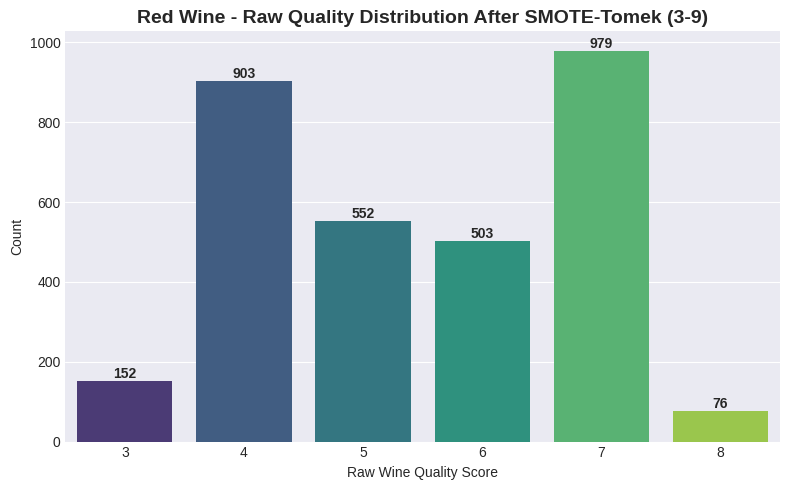

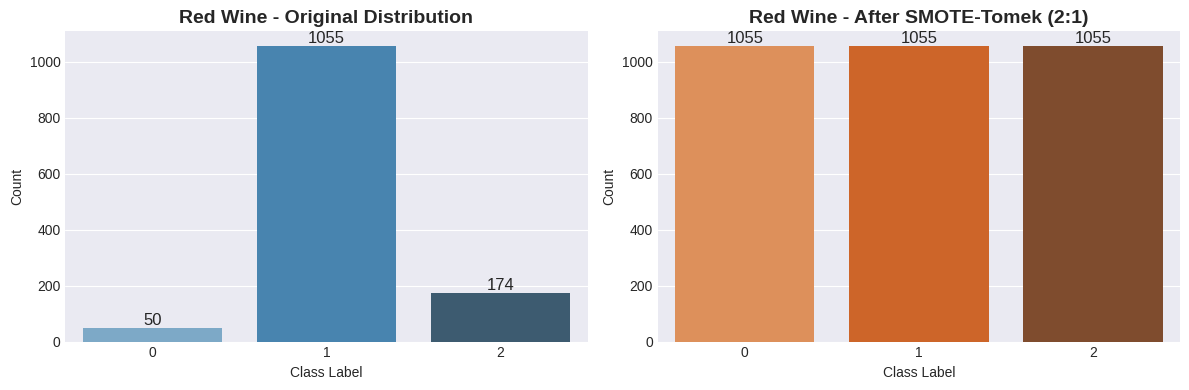


=== Starting Ensemble Training (Seeds: (42, 123, 2024, 7, 99)) ===

--- Starting Training for Seed 42 ---
Epoch 01/100 | Loss: 0.4454 | Val Acc: 0.1656
Epoch 10/100 | Loss: 0.1988 | Val Acc: 0.5000
Epoch 20/100 | Loss: 0.1495 | Val Acc: 0.5906
Epoch 30/100 | Loss: 0.1200 | Val Acc: 0.6781
Epoch 40/100 | Loss: 0.1123 | Val Acc: 0.6250
Early stopping triggered at Epoch 45.
--- Seed 42 Training Completed in 11.56 seconds | Best Val Acc: 0.6781 ---


--- Starting Training for Seed 123 ---
Epoch 01/100 | Loss: 0.4017 | Val Acc: 0.3406
Epoch 10/100 | Loss: 0.2048 | Val Acc: 0.5750
Epoch 20/100 | Loss: 0.1659 | Val Acc: 0.6156
Early stopping triggered at Epoch 27.
--- Seed 123 Training Completed in 6.90 seconds | Best Val Acc: 0.6625 ---


--- Starting Training for Seed 2024 ---
Epoch 01/100 | Loss: 0.4070 | Val Acc: 0.3594
Epoch 10/100 | Loss: 0.1912 | Val Acc: 0.4750
Epoch 20/100 | Loss: 0.1484 | Val Acc: 0.6531
Epoch 30/100 | Loss: 0.1159 | Val Acc: 0.6562
Epoch 40/100 | Loss: 0.1004 | Va

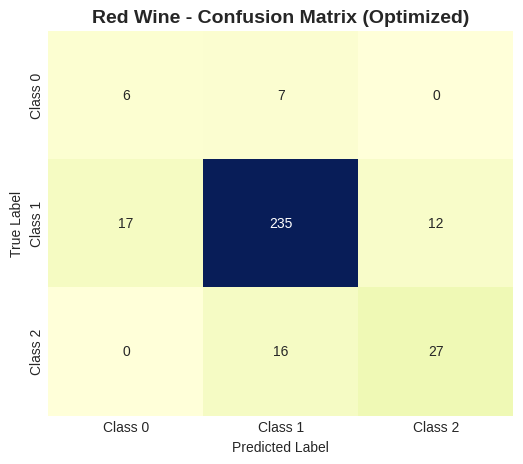

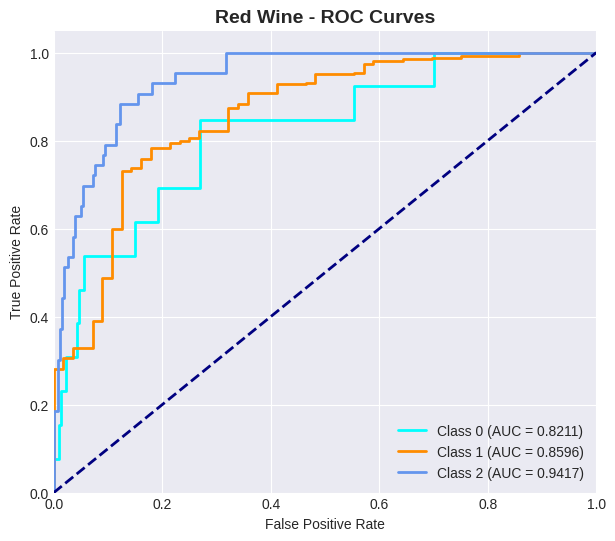

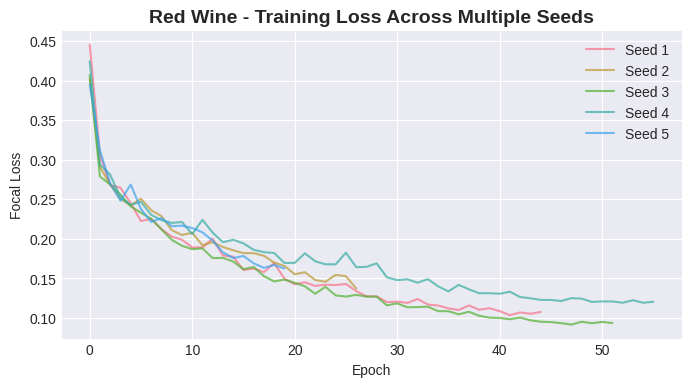


  White Wine Wine —— 2-Class Classification


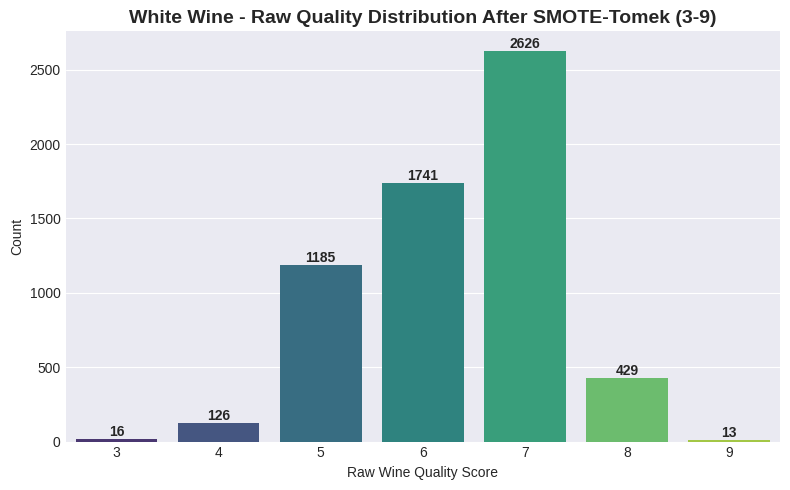

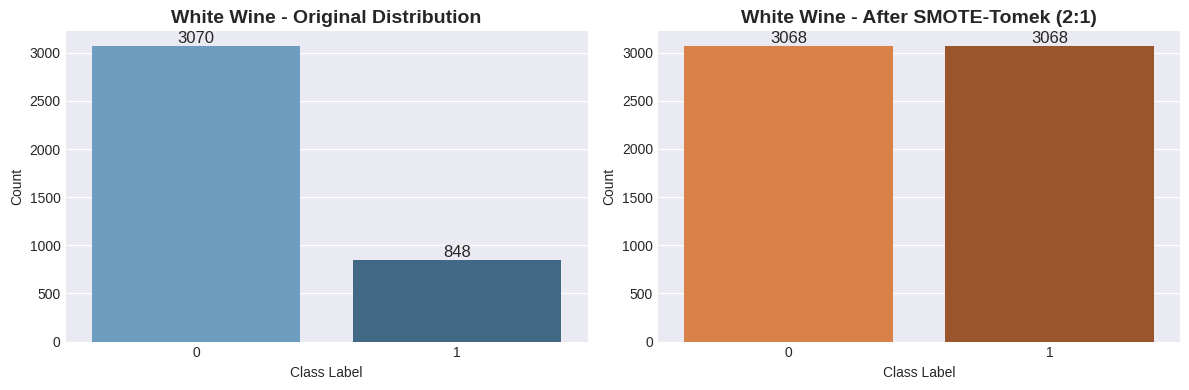


=== Starting Ensemble Training (Seeds: (42, 123, 2024, 7, 99)) ===

--- Starting Training for Seed 42 ---
Epoch 01/100 | Loss: 0.1608 | Val Acc: 0.6724
Epoch 10/100 | Loss: 0.1101 | Val Acc: 0.7939
Epoch 20/100 | Loss: 0.1041 | Val Acc: 0.8041
Early stopping triggered at Epoch 28.
--- Seed 42 Training Completed in 14.36 seconds | Best Val Acc: 0.8469 ---


--- Starting Training for Seed 123 ---
Epoch 01/100 | Loss: 0.1473 | Val Acc: 0.5878
Epoch 10/100 | Loss: 0.1083 | Val Acc: 0.8367
Epoch 20/100 | Loss: 0.1027 | Val Acc: 0.7939
Epoch 30/100 | Loss: 0.0990 | Val Acc: 0.8204
Early stopping triggered at Epoch 32.
--- Seed 123 Training Completed in 16.28 seconds | Best Val Acc: 0.8561 ---


--- Starting Training for Seed 2024 ---
Epoch 01/100 | Loss: 0.1481 | Val Acc: 0.7133
Epoch 10/100 | Loss: 0.1133 | Val Acc: 0.8296
Epoch 20/100 | Loss: 0.1027 | Val Acc: 0.8276
Epoch 30/100 | Loss: 0.0985 | Val Acc: 0.8255
Early stopping triggered at Epoch 37.
--- Seed 2024 Training Completed in 18.

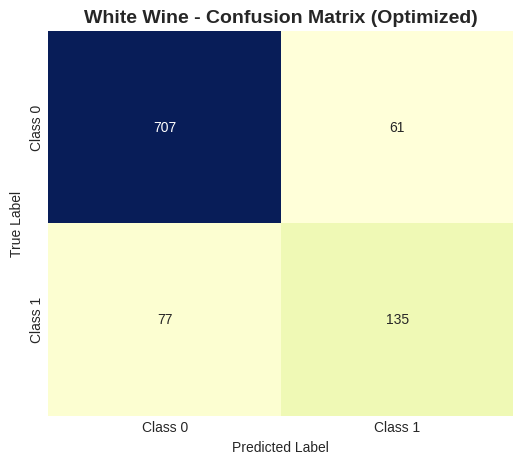

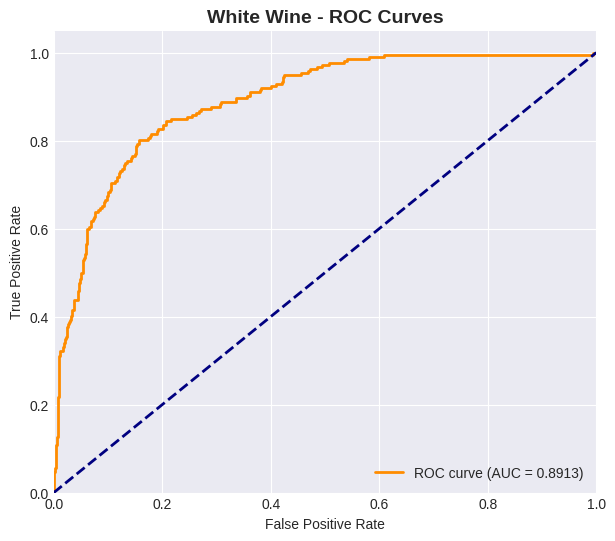

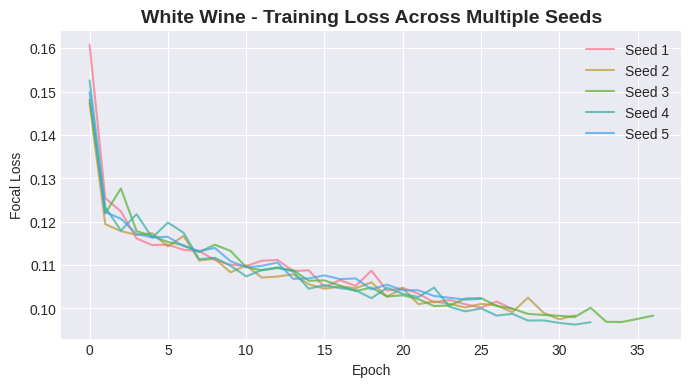


  Generating overall model performance summary plot...


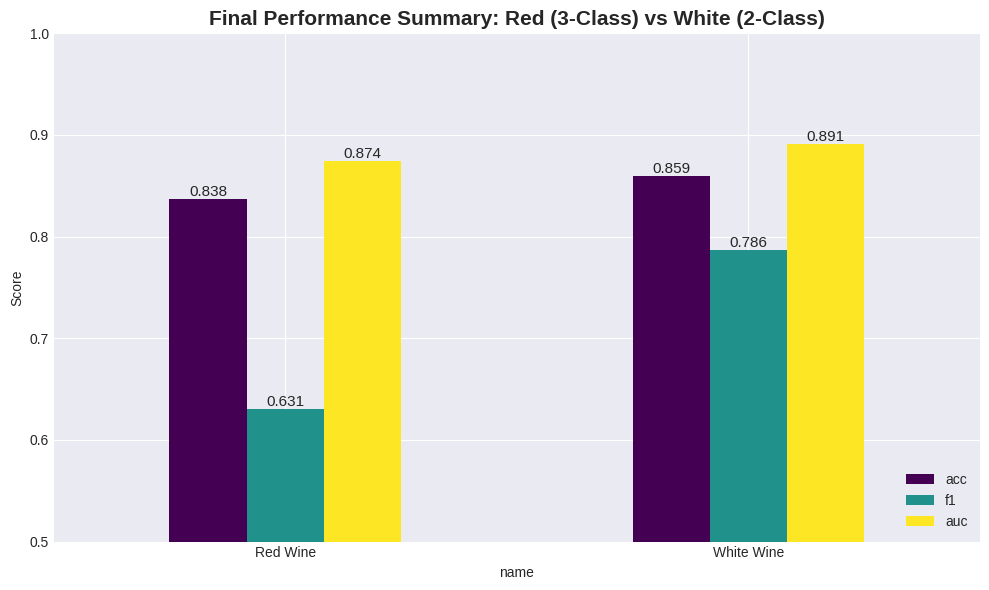

                 acc        f1       auc
name                                    
Red Wine    0.837500  0.630751  0.874137
White Wine  0.859184  0.786424  0.891307


In [60]:
# ============================================================
# 7. Main Execution
# ============================================================
if __name__ == "__main__":
    red_df = pd.read_csv("/content/winequality-red.csv", sep=";")
    white_df = pd.read_csv("/content/winequality-white.csv", sep=";")

    # UPDATED: 18 features for feature engineering
    if "add_more_engineered_features" in globals():
        red_df = add_more_engineered_features(red_df)
        white_df = add_more_engineered_features(white_df)

    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"\u2705 GPU detected successfully: {torch.cuda.get_device_name(0)}")
    else:
        device = torch.device("cpu")
        print("\u274c GPU not detected. Training with CPU.")

    # UPDATED: The 19th and 20th feature is added during run_variety() with CatBoost & LightGBM
    print("Applying 20-feature engineering to raw datasets...")

    # Run Red Wine (3-Class Classification)
    r_red = run_variety(red_df, "Red Wine", n_classes=3, device=device)

    # Run White Wine (2-Class Classification)
    r_white = run_variety(white_df, "White Wine", n_classes=2, device=device)

    # Generate and plot performance comparison bar chart
    print("\n" + "=" * 60)
    print("  Generating overall model performance summary plot...")
    summary_df = pd.DataFrame([r_red, r_white]).set_index("name")[["acc", "f1", "auc"]]

    ax = summary_df.plot(kind="bar", figsize=(10, 6), colormap="viridis", rot=0)
    plt.title("Final Performance Summary: Red (3-Class) vs White (2-Class)", fontsize=15, fontweight="bold")
    plt.ylabel("Score")
    plt.ylim(0.5, 1.0)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=11)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    print(summary_df)